# Exercise 1 

In this exercise, we will work with the `spam.csv` data file. This file contains text and a label attached to each text. The goal is to clean the text data and then build classifcation models. 

### Exercise 1(a) (2 points)

Load the `pandas` and `numpy` libraries.

In [21]:
import pandas as pd
import numpy as np

### Exercise 1(b) (2 points)

Read the `csv` file and create a data-frame called `spam_df`.

In [22]:
spam_df = pd.read_csv('spam.csv')
spam_df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Exercise 1(c) (2 points)

Using the `string` library, remove all the punctuation of the `text` column.

In [23]:
import string

spam_df['text_clean'] = spam_df['text'].str.replace(f'[{string.punctuation}]', '', regex=True)
spam_df.head()

,label,text,text_clean
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...


### Exercise 1(d) (10 points)

Using the `nltk` library, remove stopwords and pronouns from `text_clean` and store in another column called `'text_clean_1'`. 

In [24]:
import nltk


from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))
pronouns = ['i', 'he', 'she', 'it', 'they', 'we', 'him', 'her', 'his', 'their', 'our', 'u', 'ur', 'im', 'dont', '2', 'ill', '4']

def clean_text(text):

    # Tokenize the text
    tokens = word_tokenize(text.lower())

    # Remove unwanted words
    tokens = [word for word in tokens if word not in stop_words and word not in pronouns]

    # Replacing words
    tokens = [word.replace('txt', 'text') for word in tokens]

    return ' '.join(tokens)

spam_df['text_clean_1'] = spam_df['text_clean'].apply(clean_text)
spam_df.head()

,label,text,text_clean,text_clean_1
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though


### Exercise 1(e) (10 points)

Perform Lemmatization of `text_clean_1` and store the results in another column called `text_clean_2` in the `spam_df` data frame.

In [25]:
from nltk.corpus import wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer


# Initialize the lemmatizer
lemmatizer = WordNetLemmatizer()

# Function to get the part of speech tag for lemmatization
def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)

# Function to lemmatize text
def lemmatize_text(text):
    words = word_tokenize(text)
    lemmatized_words = [lemmatizer.lemmatize(word, get_wordnet_pos(word)) for word in words]
    return ' '.join(lemmatized_words)

# Apply the function to lemmatize the text
spam_df['text_clean_2'] = spam_df['text_clean_1'].apply(lemmatize_text)
spam_df.head()

,label,text,text_clean,text_clean_1,text_clean_2
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though,nah think go usf life around though


### Exercise 1(f) (5 points)

Based on the results from part 1(f), we see digits in some of the text in `text_clean_2`. Remove all the digits from `text_clean_2` and store the results in another column `text_clean_3` in the `spam_df` data frame.

In [26]:
import re

# Function to remove numbers from text
def remove_numbers(text):
    return re.sub(r'\d+', '', text)

# Apply the function to the 'text_clean_2' column
spam_df['text_clean_3'] = spam_df['text_clean_2'].apply(remove_numbers)
spam_df.head()

,label,text,text_clean,text_clean_1,text_clean_2,text_clean_3
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni,ok lar joking wif oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say,dun say early hor c already say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though,nah think go usf life around though,nah think go usf life around though


### Exercise 1(g) (10 points) LDA (Latent Dirichlet Allocation) Feature Generation

Generate LDA features based on five topics. Use `TfidfVectorizer` to generate `TF-IDF` features with the following configuration:

```
tfidf_vectorizer = TfidfVectorizer(
    max_features=100,
    max_df=0.8,  # Remove words that appear in more than 80% of documents
    min_df=5,    # Remove words that appear in fewer than 5 documents
    stop_words='english'
)
```

Then, extract five topics using `LatentDirichletAllocation` with the following configuration:

```
# Initialize LDA with 5 topics
n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=100,
    learning_method='batch'
)
```

Then, print the words associated to each of the topics.

In [27]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import TfidfVectorizer

# first we create a TF-IDF matrix from the cleaned text data
tfidf_vectorizer = TfidfVectorizer(
    max_features=100,
    max_df=0.8,  # Remove words that appear in more than 80% of documents
    min_df=5,    # Remove words that appear in fewer than 5 documents
    stop_words='english'
)

# fit and transform the cleaned text data
tfidf_matrix = tfidf_vectorizer.fit_transform(spam_df['text_clean_3'])

print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"Number of features (words): {len(tfidf_vectorizer.get_feature_names_out())}")

TF-IDF matrix shape: (5572, 100)
Number of features (words): 100


In [28]:
# Initialize LDA with 5 topics
n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=100,
    learning_method='batch'
)

# Fit the LDA model to the TF-IDF matrix
lda_topic_features = lda_model.fit_transform(tfidf_matrix)

print(f"LDA topic features shape: {lda_topic_features.shape}")
print(lda_topic_features[:5])  # Display the first 5 rows of the topic features


LDA topic features shape: (5572, 5)
[[0.08284792 0.08284792 0.37163459 0.37982176 0.08284781]
 [0.10000008 0.10000009 0.10000009 0.59999967 0.10000007]
 [0.07458636 0.07458636 0.07458637 0.07458639 0.70165453]
 [0.59999939 0.10000015 0.10000016 0.10000018 0.10000012]
 [0.40020686 0.0830164  0.34965856 0.08410193 0.08301626]]


In [29]:
#function to display the top words for each topic
def display_topics(model, feature_names, no_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print(f"Topic {topic_idx}:")
        print(" ".join([feature_names[i] for i in topic.argsort()[:-no_top_words - 1:-1]])) 
        print()

# display the top words for each topic
no_top_words = 10
display_topics(lda_model, tfidf_vectorizer.get_feature_names_out(), no_top_words)


Topic 0:
say love day today tell work dear hey make miss

Topic 1:
like home later ask oh way claim pick watch thanks

Topic 2:
come time lor da need think na great yeah night

Topic 3:
ok ltgt want good thing wat friend lol tomorrow look

Topic 4:
text free know stop phone wait week new reply thats



### Exercise 1(h) (10 points) NMF (Non-negative Matrix Factorization) Feature Generation

Generate NMF features based on five topics. Consider the following configuration for the `NMF`:

```
# Initialize NMF with the same number of topics as LDA for comparison
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    max_iter=200,
    alpha_W=0,    # Regularization parameter for W
    alpha_H=0,    # Regularization parameter for H
    l1_ratio=0.5    # Balance between L1 and L2 regularization
)
```

Then, print the words associated to each topic.

In [30]:
# Initialize NMF with the same number of topics as LDA for comparison
from sklearn.decomposition import NMF

# Initialize NMF with the same number of topics as LDA for comparison
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    max_iter=200,
    alpha_W=0,    # Regularization parameter for W
    alpha_H=0,    # Regularization parameter for H
    l1_ratio=0.5    # Balance between L1 and L2 regularization
)

# Fit the NMF model to the TF-IDF matrix
nmf_topic_features = nmf_model.fit_transform(tfidf_matrix)

print(f"NMF topic features shape: {nmf_topic_features.shape}")
print(nmf_topic_features[:5])  # Display the first 5 rows of the topic features


NMF topic features shape: (5572, 5)
[[1.97930726e-04 5.16216618e-03 2.91780496e-03 2.57878493e-02
  1.74173853e-03]
 [0.00000000e+00 3.59549184e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00]
 [1.33899038e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00]
 [0.00000000e+00 2.13152456e-02 0.00000000e+00 5.44550786e-02
  1.73130233e-02]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 4.57753697e-02
  0.00000000e+00]]


In [31]:
print(f"NMF topics with top words:")
display_topics(nmf_model, tfidf_vectorizer.get_feature_names_out(), no_top_words)

NMF topics with top words:
Topic 0:
text free stop mobile reply win phone new week nokia

Topic 1:
ok lor say ask wan leave wat home later msg

Topic 2:
come home want time tomorrow ask pick tell work da

Topic 3:
like know good day love time want need say think

Topic 4:
ltgt min say send msg buy sent try pls hi



### Exercise 1(i) (10 points) Using Topic Features for Classification

Train and evaluate three `LogisticRegression` models as follows:

- Using LDA features as input.
- Using NMF features as input.
- Combine LDA + NMF features as input.

Evaluate the three models over a five-fold cross validation strategy.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


y = spam_df['label'].map({'ham': 0, 'spam': 1})

# LDA features only 
X_lda = lda_topic_features

# NMF features only
X_nmf = nmf_topic_features

# Combine LDA and NMF features
X_combined = np.hstack((X_lda, X_nmf))


print('comparing classification performance using diferent topic features')
print('=' * 60)


# cross-validation setup
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))

# evaluate ALL features
feature_sets = {
    'LDA features only': X_lda,
    'NMF features only': X_nmf,
    'Combined LDA + NMF features': X_combined
}

results = {}
for name, X in feature_sets.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
    results[name] = scores
    print(f"{name}: Mean accuracy = {scores.mean():.4f}, Std = {scores.std():.4f}")

print('=' * 60 )
print('\nSummary of results:')
for name, scores in results.items():
    print(f"{name}: Mean accuracy = {scores.mean():.4f}, Std = {scores.std():.4f}")



comparing classification performance using diferent topic features
LDA features only: Mean accuracy = 0.8939, Std = 0.0050
NMF features only: Mean accuracy = 0.9069, Std = 0.0035
Combined LDA + NMF features: Mean accuracy = 0.9239, Std = 0.0031

Summary of results:
LDA features only: Mean accuracy = 0.8939, Std = 0.0050
NMF features only: Mean accuracy = 0.9069, Std = 0.0035
Combined LDA + NMF features: Mean accuracy = 0.9239, Std = 0.0031


### Exercise 1(j) (15 points) K-means + BERT Topic Modeling

Generate topic features using K-means clustering on BERT embeddings. This approach:
1. Uses BERT to create dense semantic embeddings of the text
2. Applies K-means clustering to group similar documents
3. Creates features based on cluster assignments and distances

This method often captures semantic relationships better than traditional bag-of-words approaches.

In [33]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [34]:
print("Loading BERT model...")
# Using a smaller, faster model for illustration purposes
bert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Generating the embedding for the cleaned text data
bert_embeddings = bert_model.encode(spam_df['text_clean_3'].tolist(),
                                    show_progress_bar=True,
                                    batch_size=32)

print(f"BERT embeddings shape: {bert_embeddings.shape}")
print(f"Each document is represented by a {bert_embeddings.shape[1]}-dimensional vector.")

Loading BERT model...


Batches:   0%|          | 0/175 [00:00<?, ?it/s]

BERT embeddings shape: (5572, 384)
Each document is represented by a 384-dimensional vector.


In [35]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


y = spam_df['label'].map({'ham': 0, 'spam': 1})

# LDA features only 
X_lda = lda_topic_features

# NMF features only
X_nmf = nmf_topic_features

# Combine LDA and NMF features
X_combined = np.hstack((X_lda, X_nmf))


print('comparing classification performance using diferent topic features')
print('=' * 60)


# cross-validation setup
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))

# evaluate ALL features
feature_sets = {
    'LDA features only': X_lda,
    'NMF features only': X_nmf,
    'Combined LDA + NMF features': X_combined
}

results = {}
for name, X in feature_sets.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
    results[name] = scores
    print(f"{name}: Mean accuracy = {scores.mean():.4f}, Std = {scores.std():.4f}")

print('=' * 60 )
print('\nSummary of results:')
for name, scores in results.items():
    print(f"{name}: Mean accuracy = {scores.mean():.4f}, Std = {scores.std():.4f}")

comparing classification performance using diferent topic features
LDA features only: Mean accuracy = 0.8939, Std = 0.0050
NMF features only: Mean accuracy = 0.9069, Std = 0.0035
Combined LDA + NMF features: Mean accuracy = 0.9239, Std = 0.0031

Summary of results:
LDA features only: Mean accuracy = 0.8939, Std = 0.0050
NMF features only: Mean accuracy = 0.9069, Std = 0.0035
Combined LDA + NMF features: Mean accuracy = 0.9239, Std = 0.0031


Finding optimal number of clusters...
Clusters: 2, Inertia: 4564.92, Silhouette: 0.028
Clusters: 3, Inertia: 4494.86, Silhouette: 0.021
Clusters: 4, Inertia: 4446.40, Silhouette: 0.019
Clusters: 5, Inertia: 4404.37, Silhouette: 0.016
Clusters: 6, Inertia: 4363.66, Silhouette: 0.017
Clusters: 7, Inertia: 4329.32, Silhouette: 0.018
Clusters: 8, Inertia: 4296.51, Silhouette: 0.019
Clusters: 9, Inertia: 4263.95, Silhouette: 0.019
Clusters: 10, Inertia: 4242.82, Silhouette: 0.020


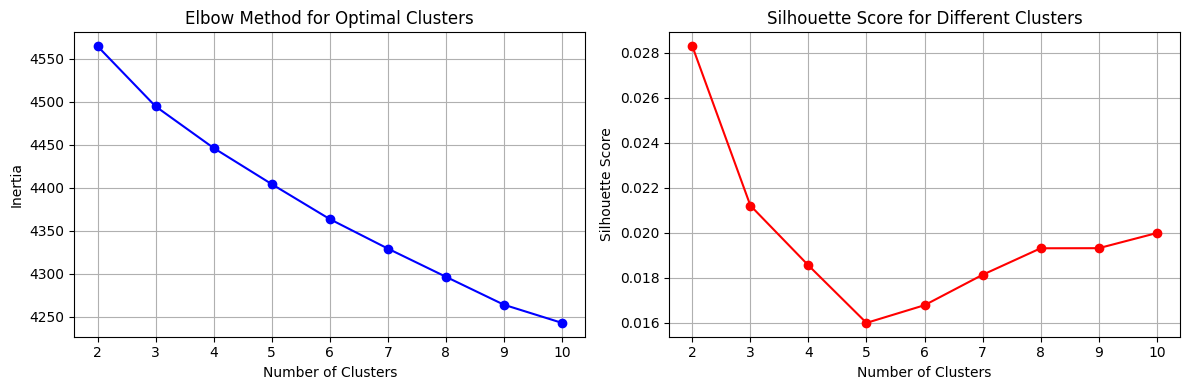


Optimal number of clusters based on silhouette score: 2


In [39]:
import matplotlib.pyplot as plt

# Step 2: Find optimal number of clusters using elbow method and silhouette score
print("Finding optimal number of clusters...")

# Test different numbers of clusters
cluster_range = range(2, 11)
inertias = []
silhouette_scores = []

for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(bert_embeddings)
    
    inertias.append(kmeans.inertia_)
    silhouette_avg = silhouette_score(bert_embeddings, cluster_labels)
    silhouette_scores.append(silhouette_avg)
    
    print(f"Clusters: {n_clusters}, Inertia: {kmeans.inertia_:.2f}, Silhouette: {silhouette_avg:.3f}")

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Elbow plot
ax1.plot(cluster_range, inertias, 'bo-')
ax1.set_xlabel('Number of Clusters')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method for Optimal Clusters')
ax1.grid(True)

# Silhouette score plot
ax2.plot(cluster_range, silhouette_scores, 'ro-')
ax2.set_xlabel('Number of Clusters')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score for Different Clusters')
ax2.grid(True)

plt.tight_layout()
plt.show()

# Choose optimal number of clusters (you can adjust this based on the plots)
optimal_clusters = cluster_range[np.argmax(silhouette_scores)]
print(f"\nOptimal number of clusters based on silhouette score: {optimal_clusters}")

In [36]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Step 1: BERT embeddings
# BERT uses context, so the raw text usually works better than the cleaned text
bert_model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = bert_model.encode(spam_df['text'].tolist(), show_progress_bar=True, batch_size=64)
print('Embedding shape:', embeddings.shape)

# Step 2: K-means clustering (same number of topics as LDA/NMF)
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings)

# Step 3: features from cluster assignments and distances
cluster_onehot = np.eye(n_clusters)[cluster_labels]   # which cluster each document is in
cluster_dist = kmeans.transform(embeddings)           # distance to every centroid
kmeans_features = np.hstack([cluster_onehot, cluster_dist])
print('K-means feature shape:', kmeans_features.shape)

# Look at each cluster: size, % spam, and a few example messages
spam_df['bert_cluster'] = cluster_labels
for k in range(n_clusters):
    subset = spam_df[spam_df['bert_cluster'] == k]
    print(f"\nCluster {k}: {len(subset)} docs, {(subset['label'] == 'spam').mean():.1%} spam")
    for t in subset['text'].head(3):
        print('   -', t[:80])

# Evaluate with the same 5-fold logistic regression setup as 1(i)
y = (spam_df['label'] == 'spam').astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_km = StandardScaler().fit_transform(kmeans_features)
scores = cross_val_score(LogisticRegression(max_iter=1000), X_km, y, cv=cv, scoring='accuracy')
print(f"\nK-means + BERT accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")


Batches:   0%|          | 0/88 [00:00<?, ?it/s]

Embedding shape: (5572, 384)
K-means feature shape: (5572, 10)

Cluster 0: 1474 docs, 1.3% spam
   - Nah I don't think he goes to usf, he lives around here though
   - Even my brother is not like to speak with me. They treat me like aids patent.
   - Is that seriously how you spell his name?

Cluster 1: 1064 docs, 1.8% spam
   - Go until jurong point, crazy.. Available only in bugis n great world la e buffet
   - Ffffffffff. Alright no way I can meet up with you sooner?
   - I'm back &amp; we're packing the car now, I'll let you know if there's room

Cluster 2: 993 docs, 66.5% spam
   - Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 8
   - FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some
   - As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been 

Cluster 3: 983 docs, 0.8% spam
   - I'm gonna be home soon and i don't want to talk about this stuff anymore tonight
   - I've been searching for the ri